In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error as mse
from skimage.metrics import structural_similarity as ssim

1.Загрузите изображение в оттенках серого sar_1_gray.jpg.

In [ ]:
image = cv2.imread('sar_1_gray.jpg',cv2.IMREAD_GRAYSCALE)
plt.imshow(image,cmap='gray')
plt.title('Original')

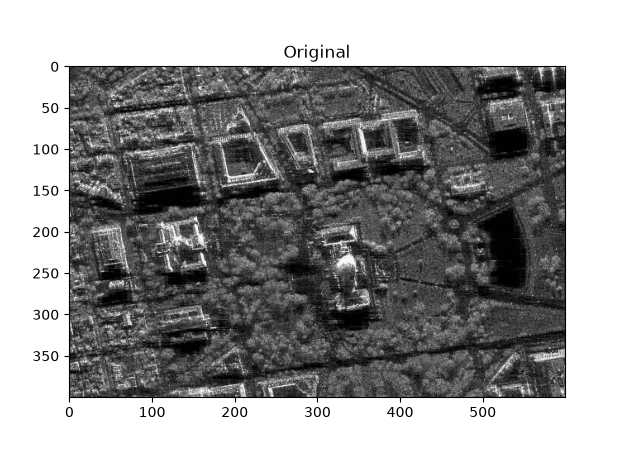

2. Постройте гистограмму

In [ ]:
histSize = 256
histRange = (0, 256)
hist = cv2.calcHist([image], [0], None, [histSize], histRange)

plt.plot(hist, color='red')

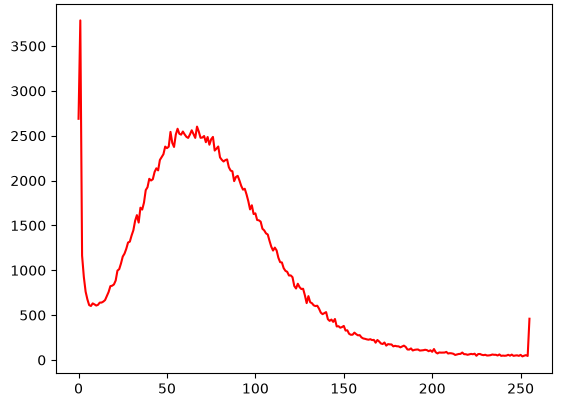

3.реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.

In [ ]:
def gamma_correction(image, gamma=1.0):
    invGamma = 1.0 / gamma
    table = ((np.arange(256)/255.0) ** invGamma * 255).astype(np.uint8)
    return cv2.LUT(image, table)

In [ ]:

imageLowGamma = gamma_correction(image,0.5)
imageHighGamma = gamma_correction(image,2)

plt.subplot(1,3,1); plt.imshow(image, cmap='gray'); plt.title("Original")
plt.subplot(1, 3, 2); plt.imshow(imageLowGamma, cmap='gray');plt.title('Gamma:0.5')
plt.subplot(1, 3, 3); plt.imshow(imageHighGamma, cmap='gray');plt.title('Gamma:2.0')


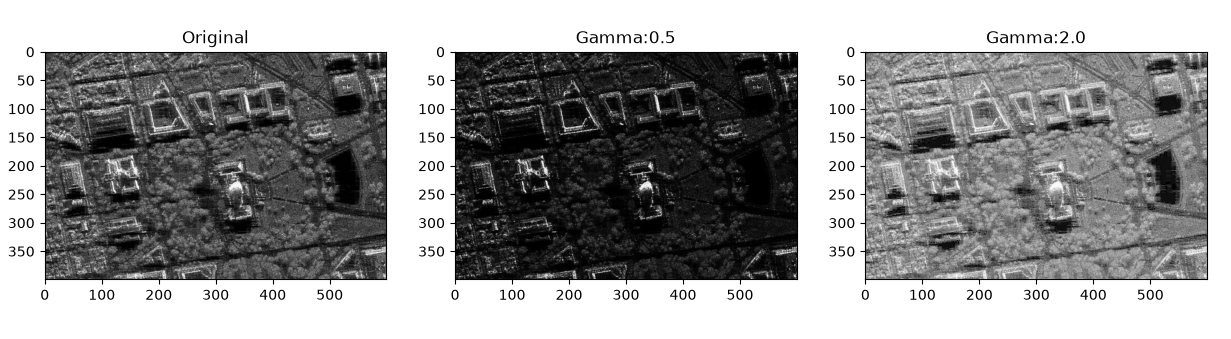

4.Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.

In [ ]:
mseLow = mse(image,imageLowGamma)
ssimLow = ssim(image,imageLowGamma)

mseHigh = mse(image,imageHighGamma)
ssimHigh = ssim(image,imageHighGamma)

print(f"Low Gamma(0.5): MSE = {mseLow:.2f}, SSIM = {ssimLow:.4f}")
print(f"High Gamma(2.0): MSE = {mseHigh:.2f}, SSIM = {ssimHigh:.4f}")

Low Gamma(0.5): MSE = 2383.76, SSIM = 0.5270
High Gamma(2.0): MSE = 3250.43, SSIM = 0.7875

5.реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.

In [ ]:
def equalize(img):
    hist, _ = np.histogram(img.ravel(), bins=256, range=[0, 256])
    cumsum = hist.cumsum()
    mcumsum = cumsum[cumsum > 0].min()
    pixels = img.shape[0] * img.shape[1]
    equalized = np.round((cumsum - mcumsum) / (pixels - mcumsum) * 255).astype(
        np.uint8
    )
    return equalized[img]

In [ ]:
eq_image = equalize(image)

Low Gamma (0.5) : MSE = 2383.76, SSIM = 0.5270
High Gamma (2.0): MSE = 3250.43, SSIM = 0.7875
Equalized       : MSE = 4021.80, SSIM = 0.6991

In [ ]:
plt.figure(figsize=[16, 4])

plt.subplot(1, 4, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")

plt.subplot(1, 4, 2)
plt.imshow(imageLowGamma, cmap="gray")
plt.title("Gamma: 0.5")

plt.subplot(1, 4, 3)
plt.imshow(imageHighGamma, cmap="gray")
plt.title("Gamma: 2.0")

plt.subplot(1, 4, 4)
plt.imshow(eq_image, cmap="gray")
plt.title("Equalized")

plt.show()

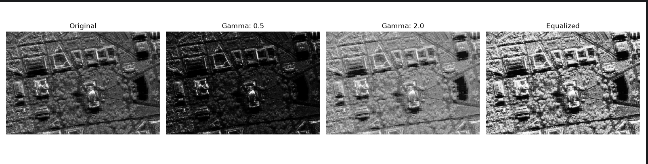

6.Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.

In [ ]:
thresholds = [50, 100, 150, 200]

plt.figure(figsize=(16, 4))

for i, t in enumerate(thresholds, 1):
    _, t_image = cv2.threshold(image, t, 255, cv2.THRESH_BINARY)
    plt.subplot(1, 4, i)
    plt.imshow(t_image, cmap="gray")
    plt.title(f"Threshold = {t}")


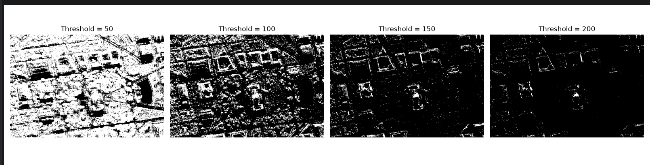